# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [2]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "rating_missing_pct": float(round(df["rating"].isna().mean() * 100, 1)),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987, 'columns': 15, 'duplicate_rows': 70, 'rating_missing_pct': 27.6, 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


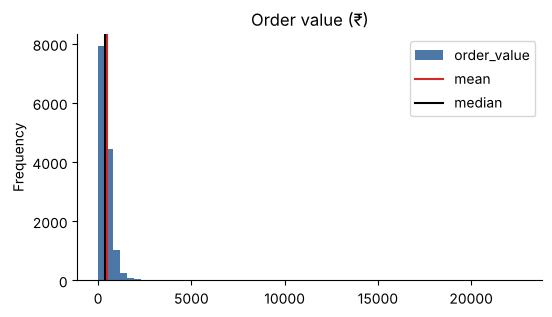

In [3]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [4]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

city
Bengaluru    21.1
Hyderabad    45.0
Pune         20.6
Name: rating, dtype: float64

**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*

(a) Insight 2 (average order value = ₹465). The mean is ₹465 but the median is only ₹358 and the skew is about 13, so a few really big orders are pulling the average up. Most customers don't spend anywhere near ₹465, so it's a misleading "typical" value. I'd rewrite it as: *"The typical order is about ₹358 (median). The mean is ₹465 because a small number of very large orders pull it up."* (There were also 70 duplicate rows which I removed, but that's only about 0.5% of the data so it doesn't change much.)

(b) 27.6% of ratings are missing, and it isn't random. Hyderabad has 45% missing vs about 21% in Bengaluru and Pune. So r = -0.32 only describes customers who bothered to rate, and Hyderabad is under-represented in it. If unhappy customers (or the ones with slow deliveries) skip rating, the real relationship could be different, so we can't say it holds for all orders.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

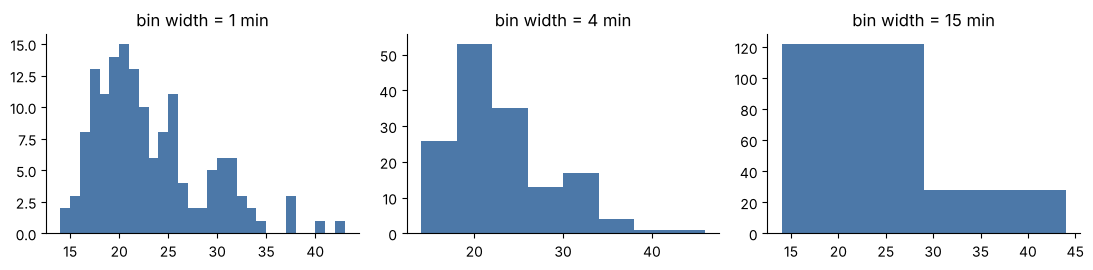

In [5]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False
best_bin_width = 4

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*

Before accepting a shape claim (like "multimodal") the analyst should redraw the plot with a few different bin widths (or a density plot) and check the shape survives, because the 1-minute bins on only 150 orders are just noise. With 4-minute bins there is one main peak with a right tail, so I'd reject the three peaks claim.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


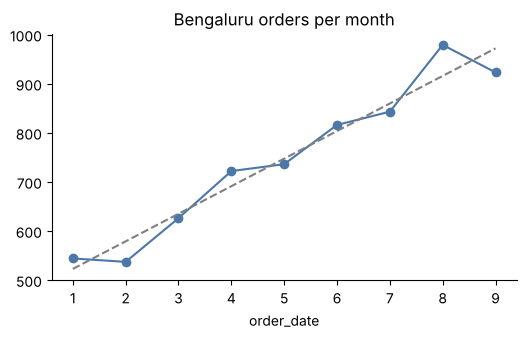

In [6]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


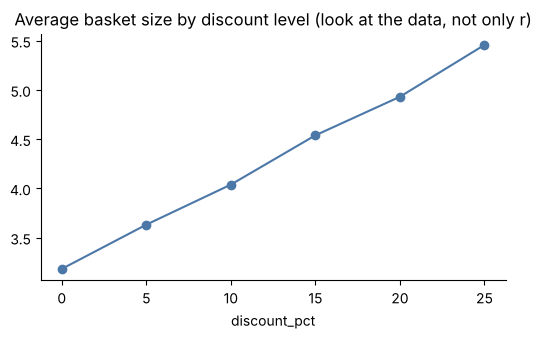

In [7]:
r_disc_items = df["discount_pct"].corr(df["items"])

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [8]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*

(a) Yes, the claim is reasonable. Monthly orders go from 544 in Jan to 923 in Sep, the fitted slope is about +56 orders per month and Kendall tau is 0.89 with p = 0.0002, so it's a real upward trend and not luck. But it's only 9 points, so I'd show the monthly points with the fitted line (not just a single number), say "about", and mention that September (923) is actually lower than August (979).

(b) The chart supports "move together": average basket size goes up steadily at every discount step, from about 3.2 items at 0% to 5.5 items at 25%, and r = 0.38 is a moderate positive correlation. But the AI can't say discounts *cause* bigger baskets. It could be the other way round (bigger baskets qualify for bigger discounts) or something else drives both, like promo days. This is observational data.

(c) The most likely false alarm is discount_pct vs loyalty_points (r = -0.022, p = 0.008). Reason 1: we tested 21 pairs, so we'd expect about 1 false positive at p < 0.05 anyway, and its p is above the Bonferroni threshold (0.05/21 = 0.0024), so it doesn't survive the correction. Reason 2: r is tiny (it explains about 0.05% of the variance) and there's no business reason for discounts to be linked to loyalty points. It's only "significant" because n is huge (about 14k rows).

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

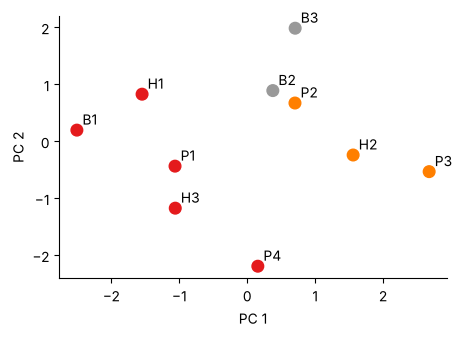

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [9]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*

With only 10 stores, k-means with k = 3 is very unstable, so each group has just 2 to 5 stores and one store moving changes the story. The groups also look a bit random: B1 does about 8.3 orders per active day, similar to B2 (8.9) and B3 (7.5), but it got put in a different group with H1 and P1 (about 5 per day or less). Also P3 and P4 are new stores with only 92 active days, which might be driving the groups instead of real "types". Before naming the segments I would re-run with different random states and values of k (and check a silhouette score), see if the groups stay the same, and look at what features actually separate them.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [10]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (hyd_month[9] / hyd_month[8] - 1) * 100
first_test = 'B'

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [11]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime[9] - ontime[8]
culprit_store = 'H2'

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


In [12]:
# Hypothesis C: were discounts cut in September?
disc = hyd.groupby(hyd["order_date"].dt.month)["discount_pct"].mean()
print(f"Hyderabad mean discount: Aug = {disc[8]:.2f}%, Sep = {disc[9]:.2f}%")

Hyderabad mean discount: Aug = 9.35%, Sep = 9.49%


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*

Hypothesis B is supported: store H2 has 0 orders in the weeks of 13 Sep and 20 Sep (and only 11 in the next week), so it's a missing-data gap. Hypothesis A is ruled out because the on-time rate only changed by about -0.3 points (89.0% to 88.7%), and C is ruled out too since the mean discount stayed about the same (9.3% vs 9.5%). D can't be tested with this data.

**Corrected insight 4:** *"Recorded Hyderabad orders fell 28% from August to September (483 to 346), but store H2 has no data for about two weeks in September, so most of the drop is a data gap. On-time delivery did not change (-0.3 points) and discounts were the same, so there is no evidence that service got worse. We need to get H2's missing data fixed before drawing any conclusion."*

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [13]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (old[3].sum() / old[2].sum() - 1) * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

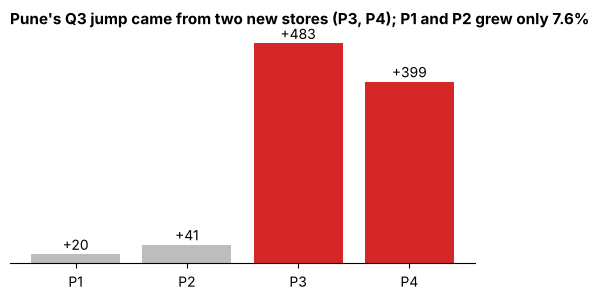

In [14]:
title = "Pune's Q3 jump came from two new stores (P3, P4); P1 and P2 grew only 7.6%"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [15]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().mul(100).round(1).unstack()
better_in_every_zone = 'Partner A'
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*

(a) *"Pune orders were 117% higher in Q3 than in Q2, but almost all of that comes from two new stores (P3 and P4) that opened in Q3. For the two stores that were open in both quarters (P1 and P2), orders grew only 7.6%. So the expansion added volume, but the 'doubling' is not growth of the existing business, and we can't call it a huge success from this."*

(b) Partner B looks better overall because it mostly gets easy orders: about 84% of Partner B's orders are Urban while 67% of Partner A's orders are Suburban, and suburban deliveries are slower for everybody. When you compare inside each zone Partner A is actually better (Urban 98.8% vs 96.9%, Suburban 81.4% vs 72.0%). This is Simpson's paradox. A careful human asks "are the two groups getting comparable orders?" and checks the comparison within subgroups (zone, distance) before accepting it. If we sent everything to B, suburban deliveries would probably get worse.

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [16]:
decisions = {
    1: "Accept",   # Bengaluru trend
    2: "Correct",   # average order value
    3: "Correct",   # Pune doubled
    4: "Reject",   # Hyderabad fell because service worsened
    5: "Reject",   # Partner B more punctual
    6: "Correct",   # delivery time vs rating
    7: "Accept",   # discount vs basket
    8: "Accept",   # suburban slower (check it yourself: df.groupby("zone")["delivery_minutes"].mean())
    9: "Reject",   # recovery prediction
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = sum(v == "Accept" for v in decisions.values())
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 3/9 | precision = 0.33 | recall = 0.43 | F1 = 0.38
Review effort spent on insights that were not fully correct: 67%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*

I accepted 3 of the 9 insights, so precision = 3/9 = 0.33, recall = 3/7 = 0.43 and F1 = 0.38. It's an assistant and not a replacement, because 6 of the 9 insights (67%) needed correcting or rejecting, so a person has to check every one before it goes to Meera. But it did point us to useful things to look at (the Hyderabad drop, Pune, the partners), which saves time as long as a human does the verifying.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [17]:
levels = {
    2: "data",   # "The average order value is ₹465."
    6: "between",   # "Longer delivery times go with lower ratings."
    9: "beyond",   # "Orders will recover in October."
}
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [18]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject',
}
user_actions

{'"Never use pie charts in this report"': 'Constrain', '"Use 5-minute bins for delivery time"': 'Adjust', '"Focus on on-time rate by city"': 'Steer', '"Keep the like-for-like Pune chart on the dashboard"': 'Pin', '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [19]:
threat = 'wrong problem'
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*

**Insight 2:** *"The typical order is about ₹358 (median). The average is ₹465 because a few very large orders pull it up, so the median is a better description of a typical customer."* (uses the right measure for a skewed distribution)

**Insight 4:** *"Recorded Hyderabad orders fell 28% from August to September (483 to 346), but store H2 has no data for about two weeks in September, so most of the drop is a data gap rather than a real fall. On-time rate barely moved (89.0% to 88.7%), so there is no evidence that service got worse. We need the missing H2 data before concluding anything."* (right scope, no causal claim)

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:*

The one I found most convincing was insight 5 (Partner B 93% vs 87%, send everything to B). It had exact numbers and the recommendation sounded very logical, so I almost didn't question it. Insight 4 also sounded good because it came with a reason. I don't think I would have caught either problem without doing the checks (splitting by zone, and looking at rows per store per week).

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:*

I'd let the AI work with little supervision on routine, easy-to-check things like the monthly order count charts by city, since mistakes are very visible and easy to undo. I'd insist on a human check for anything that changes a decision or claims a cause, like which delivery partner to use, why Hyderabad dropped, or the October forecast. I decided mostly using stakes and reversibility, because switching all orders to a partner is expensive to undo and a wrong chart isn't.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:*

For the Hyderabad gap, the tool should have shown the code and the orders by store by week next to the -28%, with a data-quality warning like "store H2 has 0 rows for 2 weeks". It should also show the sample size and which rows were excluded. For control I'd want to be able to edit the filters and re-run, undo a step, and switch off the "because..." explanations when it can't back them up.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:*

Meera is accountable for what she presents to leadership, but I'm also accountable because I signed off on the numbers. The AI and the vendor can't really be held responsible since they don't make the decision. Next time I would write down the checks I did and the limits (like the missing ratings and the H2 gap) in the report, keep the code so someone can re-run it, and mark which statements are uncertain instead of presenting everything as certain.